In [41]:
# Cell 1: Installation
!pip install -q captum

Using device: cuda

Starting Automated OCR Extraction Phase...
Found existing preprocessed CSV: /kaggle/working/Train_processed.csv
Found existing preprocessed CSV: /kaggle/working/Validation_processed.csv
Found existing preprocessed CSV: /kaggle/working/Test_processed.csv
📄 Loaded CSV: Train_processed.csv | 🖼️ Found Images: 2399 / 2400
📄 Loaded CSV: Validation_processed.csv | 🖼️ Found Images: 300 / 300
📄 Loaded CSV: Test_processed.csv | 🖼️ Found Images: 100 / 100


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 
discriminator_predictions.dense.weight            | UNEXPECTED |  | 
discriminator_predictions.dense.bias              | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Testing is starting...


Testing: 100%|██████████| 13/13 [00:04<00:00,  2.85it/s]


TEST RESULT (ResNet50 + BanglaBERT Intermediate Fusion)
Test Accuracy : 0.5200
Test Precision: 0.5312
Test Recall   : 0.5200
Test F1 Score : 0.4725


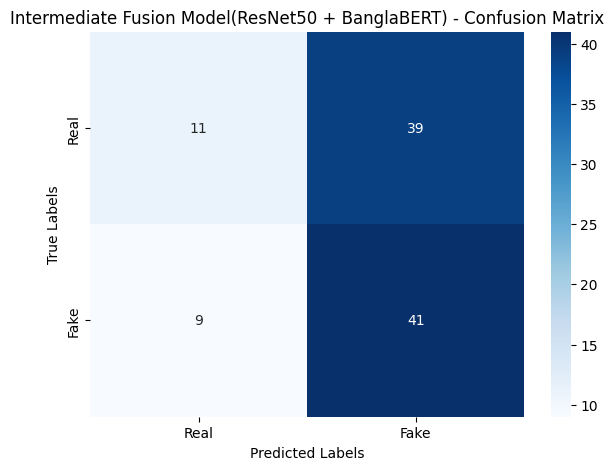


Running ResNet50 + BanglaBERT Intermediate Fusion XAI outputs...

Evaluating Sample 1 | True Label: Real


/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2495 (\N{BENGALI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2465 (\N{BENGALI LETTER DDA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2441 (\N{BENGALI LETTER U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2463 (\N{BENGALI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2488 (\N{BENGALI LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2470 (\N{BENGALI LETTER DA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: 

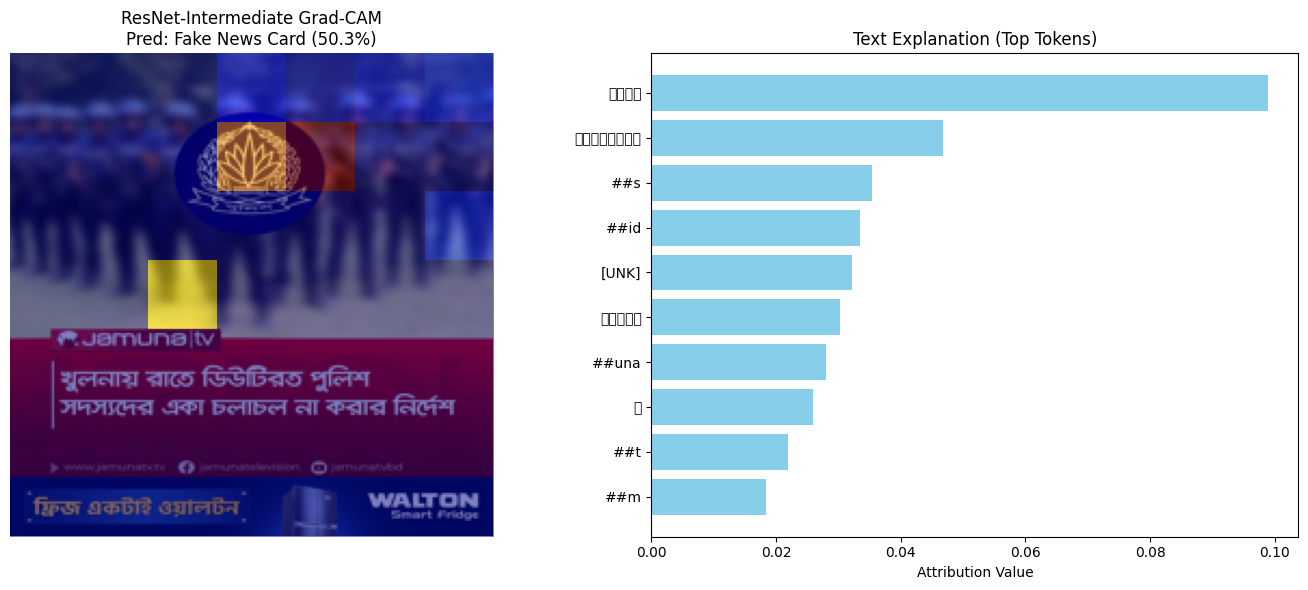


Evaluating Sample 2 | True Label: Real


/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2535 (\N{BENGALI DIGIT ONE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2534 (\N{BENGALI DIGIT ZERO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2438 (\N{BENGALI LETTER AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2482 (\N{BENGALI LETTER LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2536 (\N{BENGALI DIGIT TWO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2540 (\N{BENGALI DIGIT SIX}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2535 (\N{BENGALI DIGIT ONE}) missing from font(s) DejaVu Sans.
  fig.canva

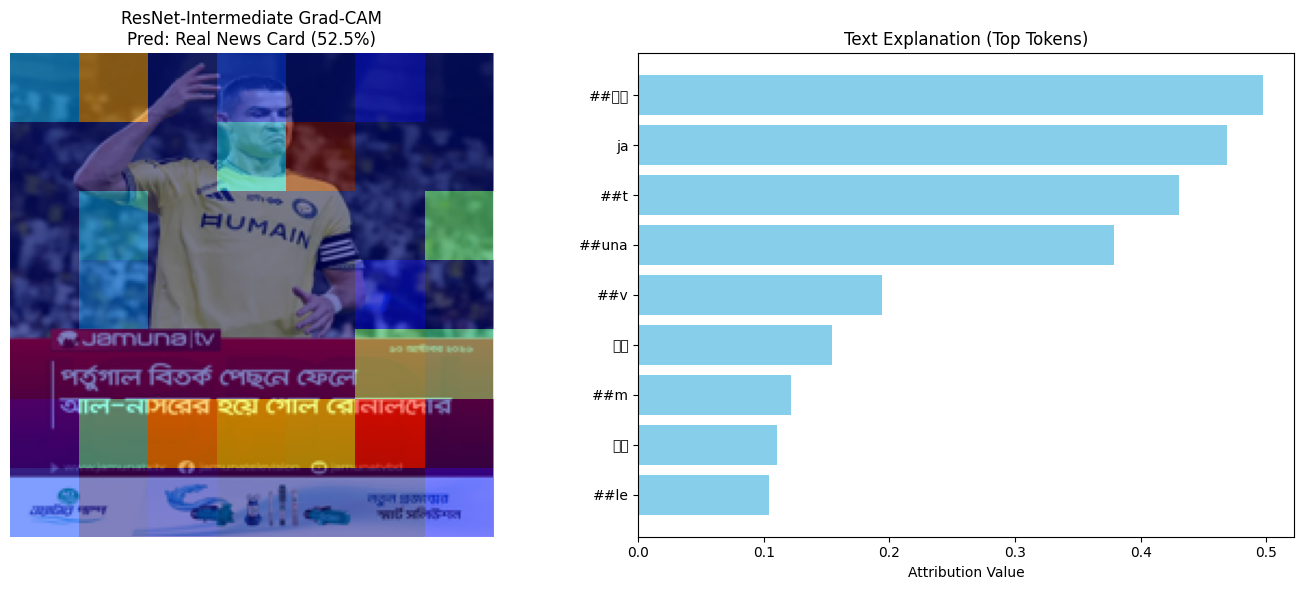


Evaluating Sample 3 | True Label: Real


/tmp/ipykernel_46/201144042.py:532: UserWarning: Glyph 2455 (\N{BENGALI LETTER GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2455 (\N{BENGALI LETTER GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


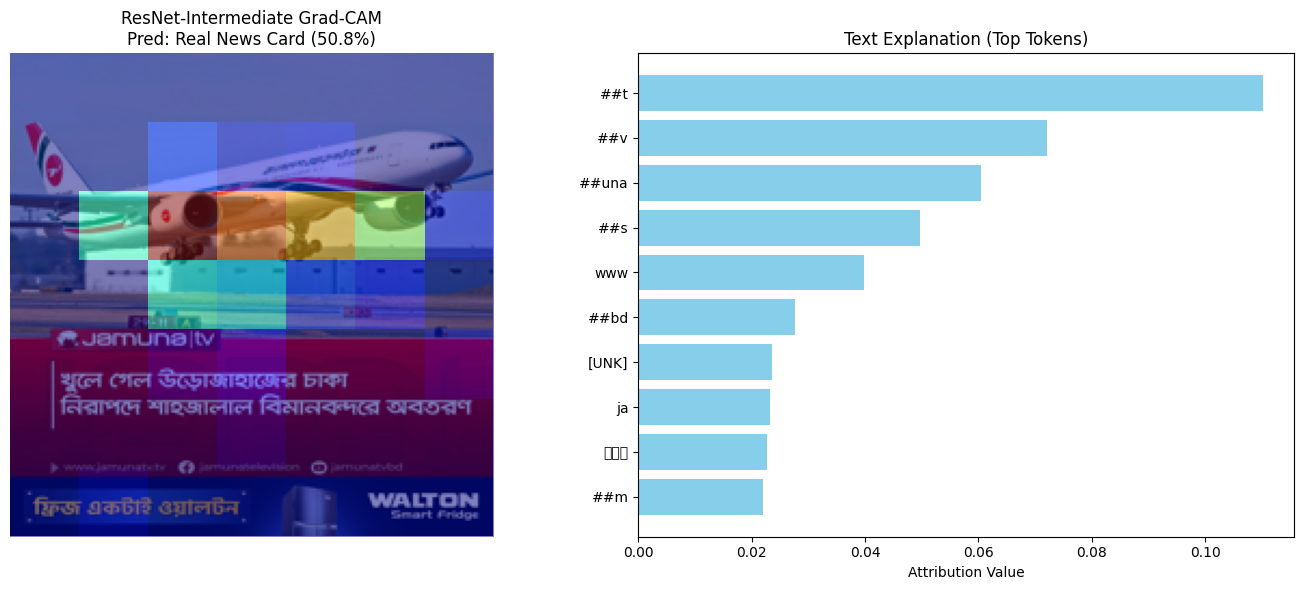

In [42]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image

import torch
from torch import nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import random
import easyocr
from captum.attr import LayerGradCam, IntegratedGradients

# ---------------------------------------------------------
# 1. Reproducibility & Device Setup
# ---------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# ---------------------------------------------------------
# 2. Paths & Hyperparameters Setup
# ---------------------------------------------------------
base_path = '/kaggle/input/datasets/nomanemployee/bengali-photocard-1/Bengali Photocard Dataset'

base_path_1 = '/kaggle/input/datasets/nomanemployee/test-sample-3/Test Sample 3'

csv_paths = {
    'train': f'{base_path}/Train.csv',      
    'test': f'{base_path_1}/Real Fake.csv',        
    'validation': f'{base_path}/Validation.csv'    
}

processed_csv_paths = {
    'train': '/kaggle/working/Train_processed.csv',      
    'test': '/kaggle/working/Test_processed.csv',        
    'validation': '/kaggle/working/Validation_processed.csv'    
}


image_dirs = {
    'train': f'{base_path}/Train',          
    'test': f'{base_path_1}/Real Fake',
    'validation': f'{base_path}/Validation'  
}

BATCH_SIZE = 8           
MAX_SEQ_LENGTH = 128    
EPOCHS = 35            
LEARNING_RATE = 2e-4  

# ---------------------------------------------------------
# 3. OCR Preprocessing Function
# ---------------------------------------------------------
# আপনার কোডের Section 3 এ এটি বসাবেন:
def clean_ocr_text(text):
    if not isinstance(text, str):
        return ""
    
    # অপ্রয়োজনীয় ক্যারেক্টার রিমুভ করা
    text = re.sub(r'[^\w\s\u0980-\u09FF।!?,.-]', ' ', text)
    
    # দাঁড়ি, কমার আশেপাশের স্পেস ঠিক করা
    text = re.sub(r'\s+([।,!?])', r'\1', text)
    
    # অতিরিক্ত স্পেস রিমুভ করা
    text = " ".join(text.split())
    
    return text

def preprocess_and_save_ocr(input_csv, image_dir, output_csv):
    if os.path.exists(output_csv):
        print(f"Found existing preprocessed CSV: {output_csv}")
        return
    def advanced_ocr_cleanup(text):
        text = clean_ocr_text(text)
    
    # কমন OCR ভুলগুলো ঠিক করার ছোট ডিকশনারি (প্রয়োজন অনুযায়ী বাড়াতে পারেন)
    replacements = {
        "৹": "",       # অপ্রয়োজনীয় বুলেট বা সাইন থাকলে
        "  ": " ",     # ডাবল স্পেস থাকলে সিঙ্গেল করা
        # আপনার ডেটাসেটে যেসব ভুল কমন পান, সেগুলো এখানে জোড়া লাগাতে পারেন
    }
    
    for wrong, right in replacements.items():
        text = text.replace(wrong, right)
        
    return text.strip()
    print(f"\nProcessing OCR for CSV: {input_csv} | Images Directory: {image_dir}")
    ocr_reader = easyocr.Reader(['bn', 'en'], gpu=torch.cuda.is_available())
    df = pd.read_csv(input_csv)
    ocr_texts = []

    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Extracting OCR Text"):
        img_id = str(row['Image_id']).strip()
        img_path = None
        for ext in ['.jpg', '.png', '.jpeg', '.JPG', '.PNG']:
            possible_path = os.path.join(image_dir, img_id + ext)
            if os.path.exists(possible_path):
                img_path = possible_path
                break

        extracted_text = ""
        if img_path:
            try:
                results = ocr_reader.readtext(img_path, detail=0)
                if results:
                    raw_text = " ".join([str(res) for res in results]).strip()
                    extracted_text = clean_ocr_text(raw_text)
            except Exception:
                extracted_text = ""
        
        ocr_texts.append(extracted_text)

    df['ocr_text'] = ocr_texts
    df.to_csv(output_csv, index=False)
    print(f"Saved preprocessed dataset to: {output_csv}")

print("\nStarting Automated OCR Extraction Phase...")
preprocess_and_save_ocr(csv_paths['train'], image_dirs['train'], processed_csv_paths['train'])
preprocess_and_save_ocr(csv_paths['validation'], image_dirs['validation'], processed_csv_paths['validation'])
preprocess_and_save_ocr(csv_paths['test'], image_dirs['test'], processed_csv_paths['test'])


# ---------------------------------------------------------
# 4. Image Augmentation & Dataset Setup
# ---------------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),  
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class MultiFusionDataset(Dataset):
    def __init__(self, processed_csv_file, original_csv_file, image_dir, transform=None):
        self.df = pd.read_csv(processed_csv_file)
        self.df.columns = self.df.columns.str.lower()
        
        orig_df = pd.read_csv(original_csv_file)
        orig_df.columns = orig_df.columns.str.lower()
        
        if 'finetuned' in orig_df.columns:
            if 'finetuned' not in self.df.columns:
                self.df = self.df.merge(orig_df[['image_id', 'finetuned']], on='image_id', how='left')
            else:
                self.df['finetuned'] = self.df['finetuned'].fillna(orig_df['finetuned'])
        
        self.image_dir = image_dir
        self.transform = transform

        image_files = os.listdir(image_dir) if os.path.exists(image_dir) else []
        self.image_names = {os.path.splitext(f)[0].strip(): os.path.join(image_dir, f) for f in image_files}
        self.df['image_path'] = self.df['image_id'].apply(lambda x: self.image_names.get(str(x).strip(), None))
        valid_count = self.df['image_path'].notna().sum()
        print(f"📄 Loaded CSV: {os.path.basename(processed_csv_file)} | 🖼️ Found Images: {valid_count} / {len(self.df)}")
        self.df = self.df.dropna(subset=['image_path']).reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'image_path']
        
        raw_description = str(self.df.loc[idx, 'finetuned']).strip() if 'finetuned' in self.df.columns and pd.notna(self.df.loc[idx, 'finetuned']) else ""
        ocr_text = str(self.df.loc[idx, 'ocr_text']).strip() if 'ocr_text' in self.df.columns and pd.notna(self.df.loc[idx, 'ocr_text']) else ""
        
        if ocr_text and raw_description:
            combined_text = raw_description if (ocr_text in raw_description or raw_description in ocr_text) else f"{ocr_text} {raw_description}"
        elif ocr_text:
            combined_text = ocr_text
        else:
            combined_text = raw_description

        label = int(self.df.loc[idx, 'label'])
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        return image, combined_text, label, img_path

train_dataset = MultiFusionDataset(processed_csv_paths['train'], csv_paths['train'], image_dirs['train'], transform=transform)
val_dataset = MultiFusionDataset(processed_csv_paths['validation'], csv_paths['validation'], image_dirs['validation'], transform=test_transform)
test_dataset = MultiFusionDataset(processed_csv_paths['test'], csv_paths['test'], image_dirs['test'], transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# ---------------------------------------------------------
# 5. RESNET50 + BANGLABERT INTERMEDIATE FUSION ARCHITECTURE
# ---------------------------------------------------------
banglabert_tokenizer = AutoTokenizer.from_pretrained('csebuetnlp/banglabert')
banglabert_model = AutoModel.from_pretrained('csebuetnlp/banglabert')

resnet50_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
img_feature_dim = resnet50_model.fc.in_features  # 2048
resnet50_model.fc = nn.Identity()

class CrossAttentionBlock(nn.Module):
    def __init__(self, text_dim, img_dim, embed_dim, num_heads=4):
        super(CrossAttentionBlock, self).__init__()
        self.proj_text = nn.Linear(text_dim, embed_dim)
        self.proj_img = nn.Linear(img_dim, embed_dim)
        
        self.cross_attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, batch_first=True)
        self.norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(0.2)

    def forward(self, text_feat, img_feat):
        t = self.proj_text(text_feat).unsqueeze(1)
        v = self.proj_img(img_feat).unsqueeze(1)
        
        attn_out, _ = self.cross_attn(query=t, key=v, value=v)
        fused = self.norm(t + self.dropout(attn_out)).squeeze(1)
        return fused

class ResNet50BanglaBERTIntermediateFusionModel(nn.Module):
    def __init__(self, img_model, text_model, img_dim, num_classes=2, embed_dim=512):
        super(ResNet50BanglaBERTIntermediateFusionModel, self).__init__()
        self.img_model = img_model
        self.text_model = text_model
        
        text_dim = self.text_model.config.hidden_size 
        
        self.intermediate_fusion = CrossAttentionBlock(text_dim, img_dim, embed_dim)
        
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 512), 
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5), 
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, images, input_ids=None, attention_mask=None, inputs_embeds=None):
        img_features = self.img_model(images)
        
        if inputs_embeds is not None:
            text_outputs = self.text_model(inputs_embeds=inputs_embeds, attention_mask=attention_mask)
        else:
            text_outputs = self.text_model(input_ids=input_ids, attention_mask=attention_mask)
            
        text_features = text_outputs.last_hidden_state[:, 0, :]
        fused_features = self.intermediate_fusion(text_features, img_features)
        
        logits = self.classifier(fused_features)
        return logits

model = ResNet50BanglaBERTIntermediateFusionModel(resnet50_model, banglabert_model, img_dim=img_feature_dim).to(device)

# ---------------------------------------------------------
# 6. Parameter Freezing Strategy
# ---------------------------------------------------------
for param in model.img_model.parameters():
    param.requires_grad = False
for name, param in model.img_model.named_parameters():
    if "layer4" in name:
        param.requires_grad = True

for param in model.text_model.parameters():
    param.requires_grad = False
for name, param in model.text_model.named_parameters():
    if "encoder.layer.10" in name or "encoder.layer.11" in name or "pooler" in name:
        param.requires_grad = True

for param in model.intermediate_fusion.parameters():
    param.requires_grad = True

for param in model.classifier.parameters():
    param.requires_grad = True

# ---------------------------------------------------------
# 7. Optimizer & Scheduler Setup
# ---------------------------------------------------------
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE, weight_decay=0.005)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
criterion = nn.CrossEntropyLoss()

'''
# ---------------------------------------------------------
# Training Loop (Uncomment if needed)
# ---------------------------------------------------------
patience = 6
patience_counter = 0
best_val_loss = float('inf')

print("\nStarting ResNet50 + BanglaBERT Intermediate Fusion Training Process...")

for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for images, texts, labels, _ in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False):
        images = images.to(device)
        labels = labels.to(device)
        
        inputs = banglabert_tokenizer(list(texts), padding='max_length', truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors='pt')
        input_ids = inputs['input_ids'].to(device)
        attention_mask = inputs['attention_mask'].to(device)
        
        optimizer.zero_grad()
        logits = model(images, input_ids=input_ids, attention_mask=attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = logits.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    
    # Validation Phase
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    
    with torch.no_grad():
        for images, texts, labels, _ in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            inputs = banglabert_tokenizer(list(texts), padding='max_length', truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors='pt')
            input_ids = inputs['input_ids'].to(device)
            attention_mask = inputs['attention_mask'].to(device)
            
            logits = model(images, input_ids=input_ids, attention_mask=attention_mask)
            val_loss_batch = criterion(logits, labels)
            val_running_loss += val_loss_batch.item()
            
            _, predicted = logits.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
            
    val_loss = val_running_loss / len(val_loader)
    val_acc = val_correct / val_total
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {train_loss:.4f} - Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f}")
    
    scheduler.step(val_loss)
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), '/kaggle/working/best_resnet50_banglabert_intermediatefusion.pth')
        print(f"   ---> Best Model Saved! (Val Loss: {val_loss:.4f})")
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("\nEarly stopping triggered!")
            break

'''
# ---------------------------------------------------------
# 8. Testing & Evaluation Phase
# ---------------------------------------------------------
print("\nTesting is starting...")
model_path = '/kaggle/working/best_resnet50_banglabert_intermediatefusion.pth'

if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    print("✅ Best saved Intermediate Fusion Model Loaded Successfully!")

model.eval()
predicted_labels, true_labels = [], []

with torch.no_grad():
    for images, texts, labels, _ in tqdm(test_loader, desc='Testing'):
        images = images.to(device)
        inputs = banglabert_tokenizer(list(texts), padding='max_length', truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors='pt')
        
        logits = model(images, input_ids=inputs['input_ids'].to(device), attention_mask=inputs['attention_mask'].to(device))
        _, predicted = logits.max(1)
        
        predicted_labels.extend(predicted.cpu().numpy())
        true_labels.extend(labels.numpy())

# ---------------------------------------------------------
# 9. Performance Metrics Evaluation
# ---------------------------------------------------------
predicted_labels = np.array(predicted_labels)
true_labels = np.array(true_labels)

accuracy = accuracy_score(true_labels, predicted_labels)
precision = precision_score(true_labels, predicted_labels, average='weighted')
recall = recall_score(true_labels, predicted_labels, average='weighted')
f1 = f1_score(true_labels, predicted_labels, average='weighted')

print(f"\nTEST RESULT (ResNet50 + BanglaBERT Intermediate Fusion)")
print(f"Test Accuracy : {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall   : {recall:.4f}")
print(f"Test F1 Score : {f1:.4f}")

conf_matrix = confusion_matrix(true_labels, predicted_labels)
plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, cmap='Blues', fmt='d', xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Intermediate Fusion Model(ResNet50 + BanglaBERT) - Confusion Matrix')
plt.show()

# ---------------------------------------------------------
# 10. EXPLAINABLE AI (XAI) MODULE FOR INTERMEDIATE FUSION
# ---------------------------------------------------------
def generate_resnet_intermediate_xai(model, image_path, text_string, target_class=None):
    model.eval()
    
    # 1. Preprocess Image
    raw_img = Image.open(image_path).convert('RGB')
    transformed_img = test_transform(raw_img).unsqueeze(0).to(device)
    
    # 2. Preprocess Text
    inputs = banglabert_tokenizer(text_string, padding='max_length', truncation=True, max_length=MAX_SEQ_LENGTH, return_tensors='pt')
    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)
    
    # 3. Model Prediction
    with torch.no_grad():
        logits = model(transformed_img, input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.softmax(logits, dim=1)
        pred_class = torch.argmax(probs, dim=1).item()
        confidence = probs[0][pred_class].item() * 100
        
    if target_class is None:
        target_class = pred_class

    class_names = {1: 'Real News Card', 0: 'Fake News Card'}
    
    # --- A. RESNET50 GRAD-CAM ---
    def forward_image_resnet(img):
        return model(img, input_ids=input_ids, attention_mask=attention_mask)

    # ResNet50-এর শেষ কনভোলিউশনাল লেয়ার (layer4[-1])
    target_layer = model.img_model.layer4[-1]
    layer_gc = LayerGradCam(forward_func=forward_image_resnet, layer=target_layer)
    attr_gradcam = layer_gc.attribute(transformed_img, target=target_class)
    
    heatmap = attr_gradcam.squeeze().cpu().detach().numpy()
    if len(heatmap.shape) == 3:
        heatmap = heatmap.mean(axis=0)
        
    heatmap = np.maximum(heatmap, 0)
    if np.max(heatmap) > 0:
        heatmap /= np.max(heatmap)
        
    # --- B. TEXT INTEGRATED GRADIENTS ---
    embedding_layer = model.text_model.get_input_embeddings()
    with torch.no_grad():
        embeddings = embedding_layer(input_ids)
    
    def forward_text(embeds):
        bsz = embeds.shape[0]
        expanded_img = transformed_img.expand(bsz, -1, -1, -1)
        expanded_mask = attention_mask.expand(bsz, -1)
        return model(expanded_img, inputs_embeds=embeds, attention_mask=expanded_mask)

    ig = IntegratedGradients(forward_text)
    
    attributions = ig.attribute(
        inputs=embeddings,
        target=target_class,
        n_steps=10,
        internal_batch_size=1
    )
    
    token_importance = attributions.sum(dim=-1).squeeze(0).cpu().detach().numpy()
    tokens = banglabert_tokenizer.convert_ids_to_tokens(input_ids[0])
    
    # --- C. PLOTTING ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Image Grad-CAM Plot
    axes[0].imshow(raw_img.resize((224, 224)))
    axes[0].imshow(heatmap, cmap='jet', alpha=0.5, extent=(0, 224, 224, 0))
    axes[0].set_title(f"ResNet-Intermediate Grad-CAM\nPred: {class_names[pred_class]} ({confidence:.1f}%)")
    axes[0].axis('off')
    
    # Text Token Importance Plot
    valid_tokens, valid_scores = [], []
    for tok, score in zip(tokens, token_importance):
        if tok not in ['[PAD]', '[CLS]', '[SEP]']:
            valid_tokens.append(tok)
            valid_scores.append(abs(score))
            
    if len(valid_tokens) > 0:
        top_indices = np.argsort(valid_scores)[-10:]
        axes[1].barh([valid_tokens[i] for i in top_indices], [valid_scores[i] for i in top_indices], color='skyblue')
    else:
        axes[1].text(0.5, 0.5, "No Text Tokens", ha='center', va='center')
        
    axes[1].set_title("Text Explanation (Top Tokens)")
    axes[1].set_xlabel("Attribution Value")
    
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 11. RUN XAI ON SAMPLE TEST IMAGES
# ---------------------------------------------------------
print("\nRunning ResNet50 + BanglaBERT Intermediate Fusion XAI outputs...")
for i in range(min(3, len(test_dataset))):
    _, text, label, img_p = test_dataset[i]
    print(f"\nEvaluating Sample {i+1} | True Label: {'Fake' if label==0 else 'Real'}")
    generate_resnet_intermediate_xai(model, img_p, text)

In [43]:
import pandas as pd
test_df = pd.read_csv('/kaggle/working/Test_processed.csv')
print("Total rows:", len(test_df))
print(test_df.head(100))
print("Non-empty OCR texts:", test_df['ocr_text'].notna().sum())

Total rows: 100
     ID Image_id Class  Label  \
0     1    img_1  Real      1   
1     2    img_2  Real      1   
2     3    img_3  Real      1   
3     4    img_4  Real      1   
4     5    img_5  Real      1   
..  ...      ...   ...    ...   
95   96   img_96  Fake      0   
96   97   img_97  Fake      0   
97   98   img_98  Fake      0   
98   99   img_99  Fake      0   
99  100  img_100  Fake      0   

                                             ocr_text  
0   িলন Jamunaltv খুলনায় রাতে ডিউটিরত পুলিশ সদস্যদ...  
1   Jamunaltv ১০ অক্টোবর ২০২৬ পর্তুগাল বিতর্ক পেছন...  
2   45 29-1 4 Jemunaltv খুলে গেল উড়োজাহাজের চাকা ন...  
3   রাজনৈতিক মূল্য দিতে হলেও ইসরায়েলের বন্ধুত্ব ছা...  
4   Jamunaltv ১০ অক্টোবর ২০২৬ রবীন্দ্রনাথের গ্রাফি...  
..                                                ...  
95  হাদির বোনের অভিযোগ- জাতিসংঘ বক্তব্যে শহীদ ওসমা...  
96  শেখ হাসিনা ফিরলে সাজানো গোছানো দেশটী ধ্বংস হয়...  
97  প্রধানমন্ত্রী তারেক রহমানের পিছনে খোঁচী দিয়ে ...  
98  13 08 26 9!0 মেয়েটী টাই